# The two-peak fallback delay $\Delta t_{\rm delay}(M_\bullet,a,e,v_\infty)$

A micro-TDE feeds **two** accretors: the companion BH1 (fast mini-disk fallback) and the central BH
BH2 (slow return).  The total fallback curve $dM/dt$ therefore has **two peaks**, and the observable of
interest is their separation
$$\Delta t_{\rm delay}=t_{\rm peak,BH2}-t_{\rm peak,BH1},\qquad
  t_{\rm peak}=2\pi M_c\,(2|\varepsilon|_{\rm edge})^{-3/2},$$
read from the high-energy edges of the frozen-in energy distributions $dM/d\varepsilon_{\rm BH1}$,
$dM/d\varepsilon_{\rm BH2}$ (no orbit integration needed; see `reduce_delay.py`).

This notebook maps $\Delta t_{\rm delay}$ (and the ratio $t_{\rm peak,BH2}/t_{\rm peak,BH1}$) over the grid,
exactly as we did for $f_\mu$: marginals vs each parameter, an $(M_\bullet,a)$ heatmap, and a scaling fit.

## 1. Setup & style

In [1]:
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.ticker as mticker
plt.rcParams.update({
    "figure.dpi":120,"savefig.dpi":150,"font.size":14,"axes.titlesize":15,"axes.labelsize":17,
    "legend.fontsize":12,"xtick.labelsize":13,"ytick.labelsize":13,
    "xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4,
    "axes.grid":False,"axes.linewidth":0.9,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
})
OI=dict(orange="#E69F00",blue="#0072B2",green="#009E73",vermillion="#D55E00",black="#000000",grey="#8C8C8C")
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
def log_minor(ax):
    for a in (ax.xaxis,):
        a.set_minor_locator(mticker.LogLocator(base=10,subs=np.arange(2,10),numticks=100)); a.set_minor_formatter(mticker.NullFormatter())
def edges(c,log=True):
    c=np.log10(c) if log else np.asarray(c,float); e=np.empty(c.size+1)
    e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-(c[1]-c[0])/2; e[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**e if log else e
print("style ready")

style ready


## 2. Load the survey (`delay_per_event.csv` from `reduce_delay.py`)

*(v2: produced by `pkg/reduce_delay.py smbh_bhstar_bundle.h5`; the scaling fit below is re-derived on the new events.)*

In [2]:
rows=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv")))
col=lambda k: np.array([float(r[k]) for r in rows])
M,a,e,frac=col("M_smbh"),col("a_bin"),col("e_bin"),col("frac")
tp1,tp2,Dt,ratio=col("t_peak_BH1"),col("t_peak_BH2"),col("Dt_delay"),col("ratio")
ok=np.isfinite(Dt)&(Dt>0)
print(f"{len(rows)} events, {ok.sum()} with a well-defined delay")
print(f"Dt_delay [yr]: median={np.median(Dt[ok]):.3e}  16-84=[{np.percentile(Dt[ok],16):.2e},{np.percentile(Dt[ok],84):.2e}]")
print(f"t_peak_BH1 median={np.nanmedian(tp1):.2e} yr (nearly fixed) ; t_peak_BH2 median={np.nanmedian(tp2):.2e} yr")

788113 events, 433514 with a well-defined delay
Dt_delay [yr]: median=4.772e-01  16-84=[3.57e-02,2.75e+01]
t_peak_BH1 median=2.57e-04 yr (nearly fixed) ; t_peak_BH2 median=4.77e-01 yr


## 3. Marginals: the two peaks and the delay vs each parameter

For each grid parameter we show the median (with 16-84 band) of $t_{\rm peak,BH1}$, $t_{\rm peak,BH2}$ and
$\Delta t_{\rm delay}$, marginalised over the other three.

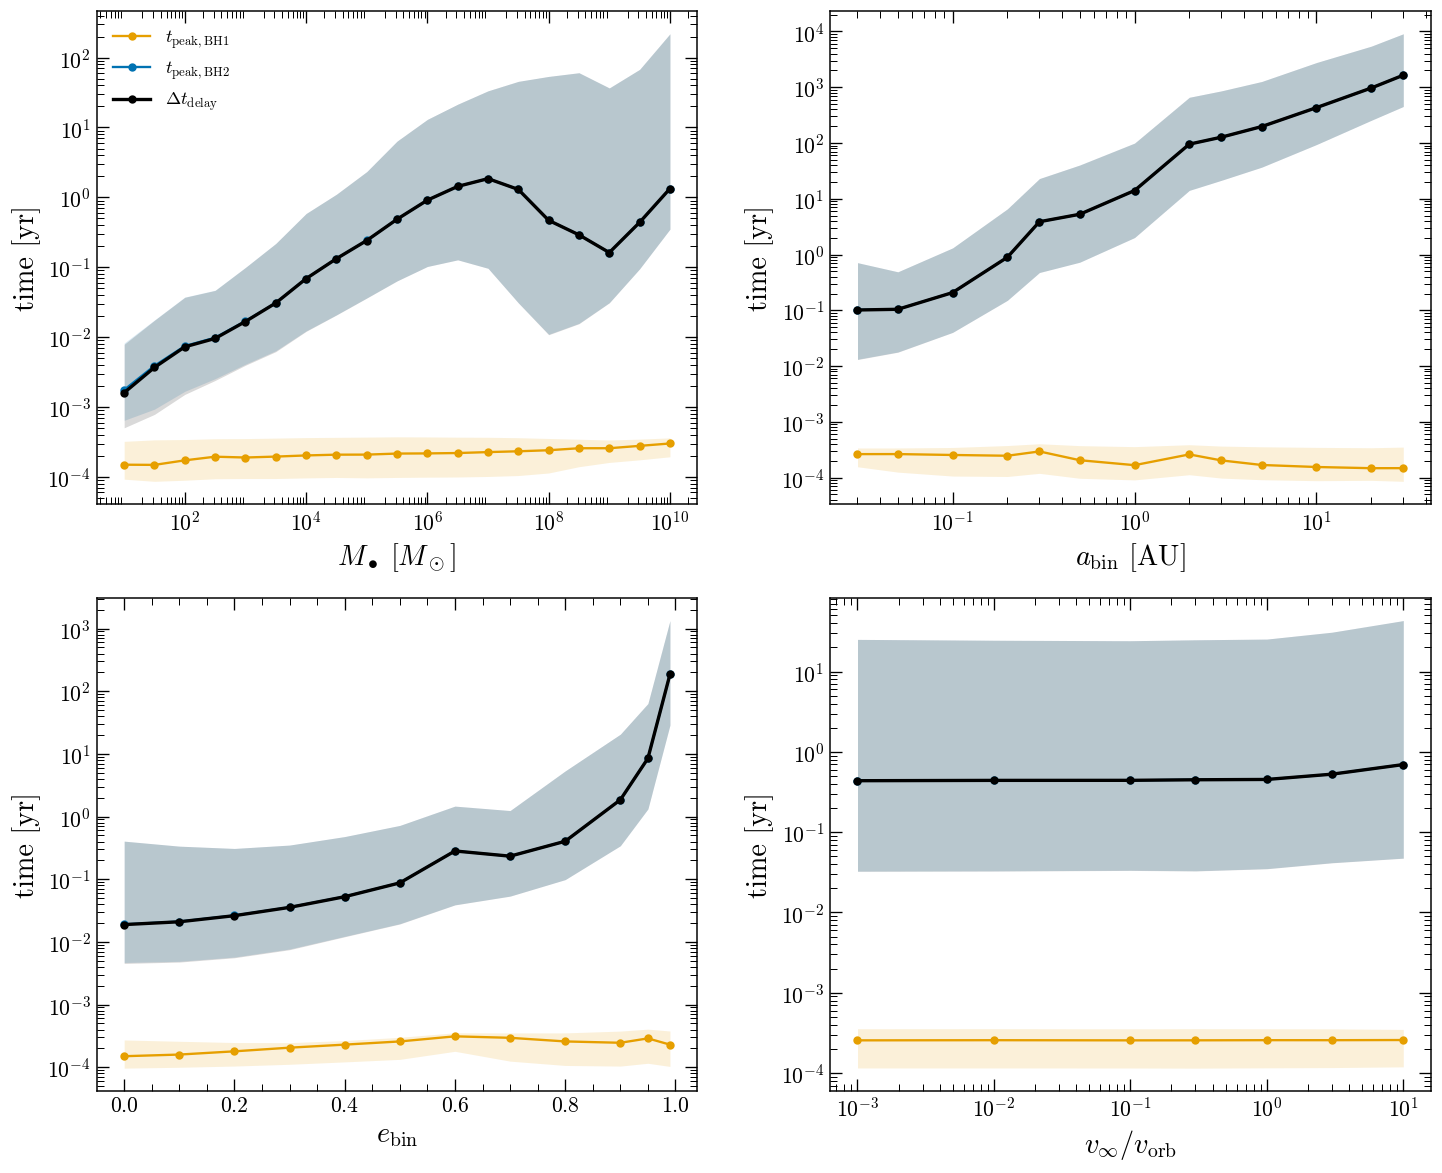

In [3]:
def marg(x, y, logx=True):
    nodes=np.unique(x); med=[]; lo=[]; hi=[]
    for v in nodes:
        yy=y[(x==v)&np.isfinite(y)&(y>0)]
        if yy.size: med.append(np.median(yy)); lo.append(np.percentile(yy,16)); hi.append(np.percentile(yy,84))
        else: med.append(np.nan); lo.append(np.nan); hi.append(np.nan)
    return nodes,np.array(med),np.array(lo),np.array(hi)

AX=[("M",M,r"$M_\bullet\;[M_\odot]$",True),("a",a,r"$a_{\rm bin}$ [AU]",True),
    ("e",e,r"$e_{\rm bin}$",False),("v",frac,r"$v_\infty/v_{\rm orb}$",True)]
fig,axs=plt.subplots(2,2,figsize=(12.5,10))
for ax,(nm,x,lab,logx) in zip(axs.flat,AX):
    for y,c,l in [(tp1,OI["orange"],r"$t_{\rm peak,BH1}$"),(tp2,OI["blue"],r"$t_{\rm peak,BH2}$"),(Dt,OI["black"],r"$\Delta t_{\rm delay}$")]:
        n,md_,lo,hi=marg(x,y,logx); g=np.isfinite(md_)
        ax.plot(n[g],md_[g],"o-",color=c,lw=2 if c==OI["black"] else 1.4,ms=4,label=l)
        ax.fill_between(n[g],lo[g],hi[g],color=c,alpha=0.15,lw=0)
    if logx: ax.set_xscale("log"); log_minor(ax)
    ax.set_yscale("log"); ax.set_xlabel(lab); ax.set_ylabel(r"time [yr]"); ax.set_box_aspect(0.82)
axs.flat[0].legend(frameon=False,fontsize=11,loc="upper left")
fig.tight_layout(); fig.savefig("delay_marginals.png",bbox_inches="tight"); fig.savefig("delay_marginals.pdf",bbox_inches="tight")
plt.show()

## 4. $\Delta t_{\rm delay}(M_\bullet,a)$ heatmap (at fixed $e$, $v$)

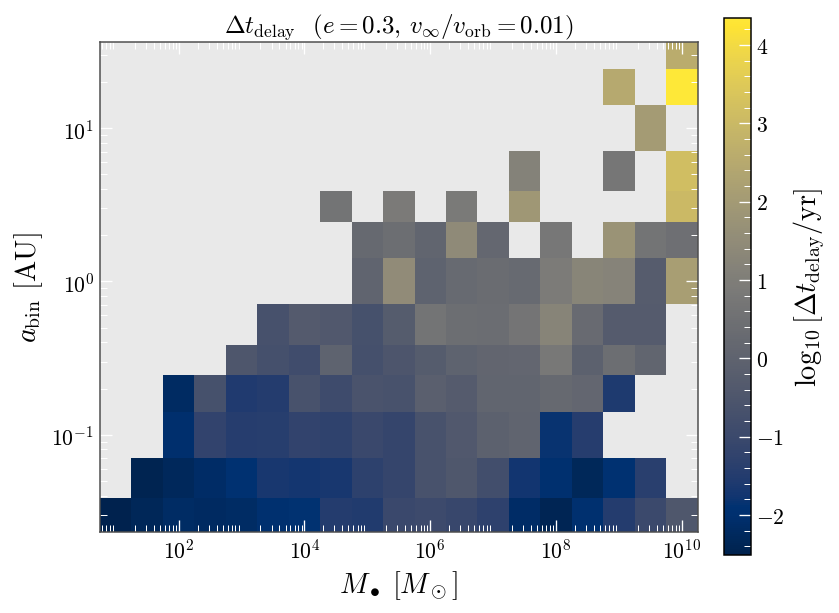

In [4]:
le=np.unique(e)[np.argmin(np.abs(np.unique(e)-0.3))]
lf=np.unique(frac)[np.argmin(np.abs(np.log10(np.unique(frac))-np.log10(0.01)))]
Mg,ag=np.unique(M),np.unique(a)
Z=np.full((len(ag),len(Mg)),np.nan)
for i,aa in enumerate(ag):
    for j,mm in enumerate(Mg):
        m=(np.isclose(M,mm))&(np.isclose(a,aa))&(np.isclose(e,le))&(np.isclose(frac,lf))&np.isfinite(Dt)&(Dt>0)
        if m.sum(): Z[i,j]=np.median(Dt[m])
fig,ax=plt.subplots(figsize=(7.2,5.6))
im=ax.pcolormesh(edges(Mg),edges(ag),np.log10(np.ma.masked_invalid(Z)),cmap=CIV,shading="flat")
ax.set_xscale("log"); ax.set_yscale("log"); log_minor(ax)
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10,subs=np.arange(2,10))); ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}$ [AU]")
ax.set_title(rf"$\Delta t_{{\rm delay}}$  ($e={le:g}$, $v_\infty/v_{{\rm orb}}={lf:g}$)"); ax.set_box_aspect(0.82)
ax.tick_params(which="both",color="white"); [s.set_edgecolor("0.3") for s in ax.spines.values()]
cb=fig.colorbar(im,ax=ax,fraction=0.046,pad=0.04); cb.set_label(r"$\log_{10}[\Delta t_{\rm delay}/{\rm yr}]$")
cb.ax.tick_params(which="both",color="white",direction="in"); cb.ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
fig.tight_layout(); fig.savefig("delay_heatmap.png",bbox_inches="tight"); fig.savefig("delay_heatmap.pdf",bbox_inches="tight")
plt.show()

## 5. Scaling fit

A weighted least-squares fit $\log_{10}\Delta t_{\rm delay}=c_0+c_M\log_{10}M_\bullet+c_a\log_{10}a+c_e\,e+c_v\log_{10}(v_\infty/v_{\rm orb})$
shows which parameters drive the delay (contrast with $f_\mu$, where $M_\bullet$ cancelled).

In [5]:
m=ok&np.isfinite(frac)
X=np.column_stack([np.ones(m.sum()),np.log10(M[m]),np.log10(a[m]),e[m],np.log10(frac[m])])
y=np.log10(Dt[m]); c,*_=np.linalg.lstsq(X,y,rcond=None)
yh=X@c; R2=1-np.sum((y-yh)**2)/np.sum((y-y.mean())**2)
names=["const","log M","log a","e","log(v/vorb)"]
print("log10(Dt_delay) ="+"".join(f"  {c[i]:+.3f}*{names[i]}" for i in range(5)))
print(f"R^2={R2:.3f}")
print("=> Dt_delay ~ M^%.2f a^%.2f  (times e, v factors)"%(c[1],c[2]))

log10(Dt_delay) =  -0.698*const  +0.113*log M  +1.253*log a  +1.194*e  +0.002*log(v/vorb)
R^2=0.689
=> Dt_delay ~ M^0.11 a^1.25  (times e, v factors)


In [6]:
# ---- scaling fit with curvature + interactions, and the intrinsic per-cell scatter ----
m = ok & np.isfinite(frac)
lM, la, ee, lv = np.log10(M[m]), np.log10(a[m]), e[m], np.log10(frac[m])
y = np.log10(Dt[m])

# baseline log-linear (for comparison)
Xlin = np.column_stack([np.ones(m.sum()), lM, la, ee, lv])
clin,*_ = np.linalg.lstsq(Xlin, y, rcond=None)
R2lin = 1 - np.sum((y-Xlin@clin)**2)/np.sum((y-y.mean())**2)

# expanded: + e^2, (log a)^2, (log M)^2, logM*log a
cols  = [np.ones(m.sum()), lM, la, ee, ee**2, la**2, lM**2, lM*la, lv]
names = ["const","log M","log a","e","e^2","(log a)^2","(log M)^2","logM*log a","log(v/vorb)"]
X = np.column_stack(cols)
c,*_ = np.linalg.lstsq(X, y, rcond=None)
yh = X@c; R2 = 1 - np.sum((y-yh)**2)/np.sum((y-y.mean())**2)

print("expanded fit  log10(Dt_delay) =")
for n,ci in zip(names,c): print(f"   {ci:+.3f}  {n}")
print(f"\nR^2:  linear = {R2lin:.3f}   ->   expanded = {R2:.3f}")
print(f"residual scatter (expanded): {np.std(y-yh):.3f} dex")

# intrinsic per-cell scatter: best-sampled fully-specified (M,a,e,v) cell
cellkey = np.column_stack([np.round(np.log10(M),4), np.round(a,5), np.round(e,4), np.round(frac,6)])
uq, inv, cnt = np.unique(cellkey[ok], axis=0, return_inverse=True, return_counts=True)
best = int(np.argmax(cnt))
dcell = np.log10(Dt[ok][inv == best])
print(f"\nbest-sampled cell has {dcell.size} events; intrinsic scatter = {np.std(dcell):.3f} dex")
# median scatter across all well-sampled cells (more representative than one cell):
scat = [np.std(np.log10(Dt[ok][inv==k])) for k in range(len(uq)) if cnt[k] >= 10]
print(f"median intrinsic per-cell scatter (cells with >=10 events): {np.median(scat):.3f} dex")

expanded fit  log10(Dt_delay) =
   -2.940  const
   +0.604  log M
   +0.609  log a
   +0.745  e
   +0.726  e^2
   +0.208  (log a)^2
   -0.030  (log M)^2
   +0.087  logM*log a
   +0.000  log(v/vorb)

R^2:  linear = 0.689   ->   expanded = 0.703
residual scatter (expanded): 0.777 dex



best-sampled cell has 1257 events; intrinsic scatter = 0.214 dex


median intrinsic per-cell scatter (cells with >=10 events): 0.669 dex


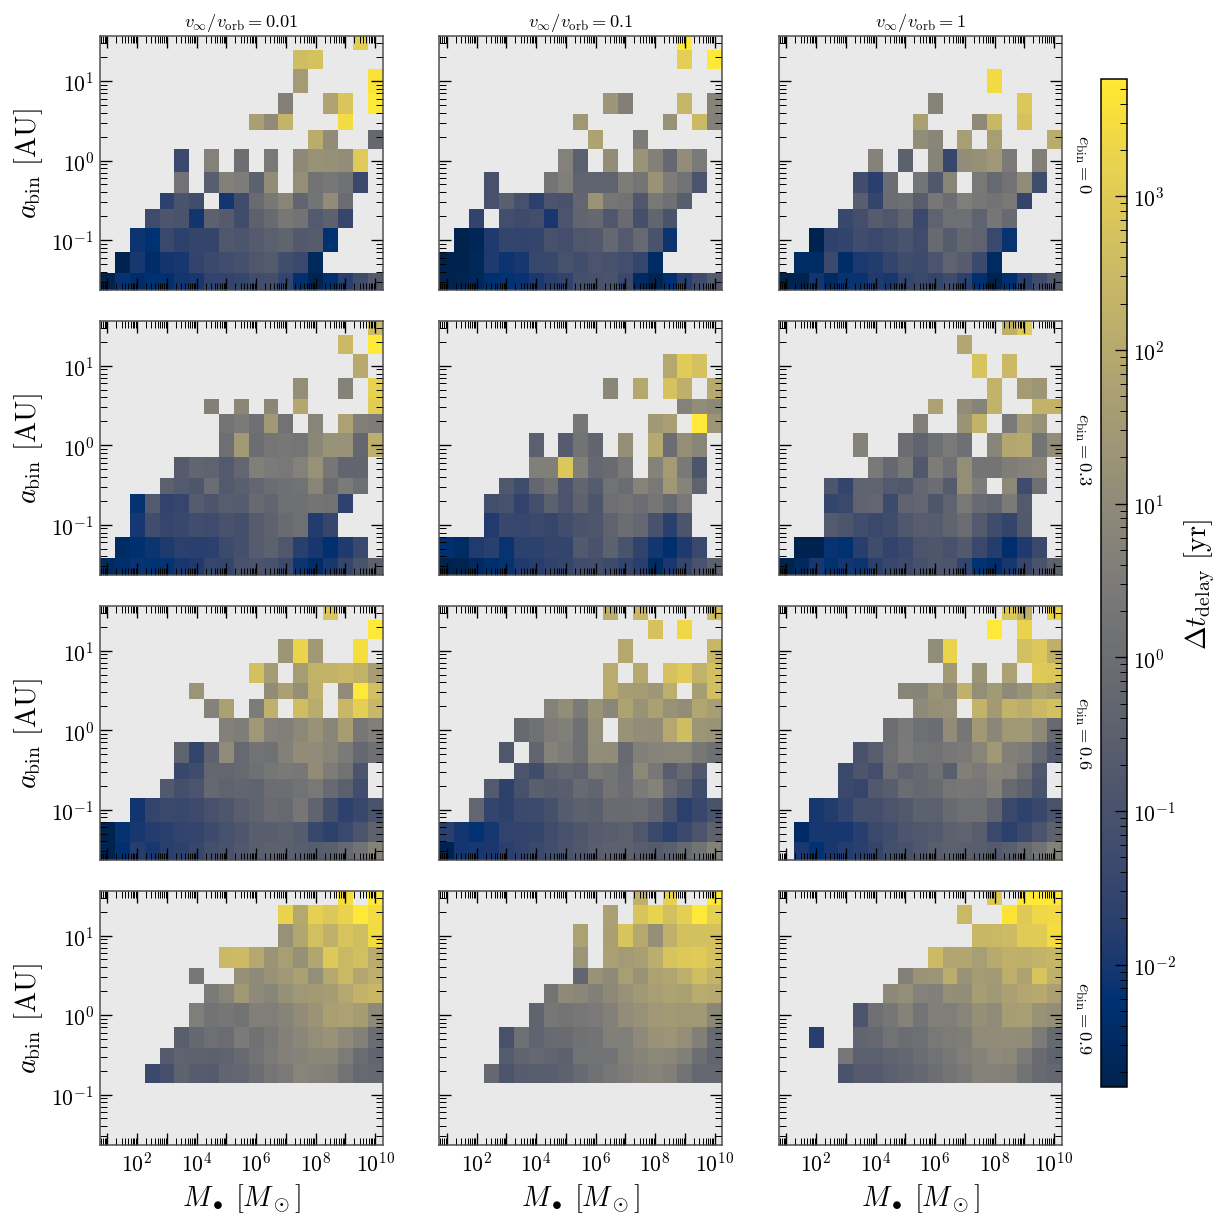

In [7]:
# ---- grid of Delta t_delay(M,a) heatmaps over (e_bin, v_inf/v_orb) pairs ----
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm
E_SHOW = [0.0, 0.3, 0.6, 0.9]          # eccentricity rows    (edit these)
V_SHOW = [1e-2, 1e-1, 1.0]             # v_inf/v_orb columns  (edit these)

def _even_pow(val, pos):               # label only even powers of ten -> one label / 2 decades
    if val <= 0: return ""
    ex = np.log10(val)
    if abs(ex-round(ex)) > 1e-3: return ""
    ex = int(round(ex)); return rf"$10^{{{ex}}}$" if ex % 2 == 0 else ""

Mg, ag = np.unique(M), np.unique(a); eN, fN = np.unique(e), np.unique(frac)
ok = np.isfinite(Dt) & (Dt > 0)
def grid_Z(ev, fv):
    en = eN[np.argmin(np.abs(eN-ev))]; fn = fN[np.argmin(np.abs(np.log10(fN)-np.log10(fv)))]
    Z = np.full((len(ag), len(Mg)), np.nan)
    for i, aa in enumerate(ag):
        for j, mm in enumerate(Mg):
            m = ok & np.isclose(M, mm) & np.isclose(a, aa) & np.isclose(e, en) & np.isclose(frac, fn)
            if m.sum(): Z[i, j] = np.median(Dt[m])
    return Z, en, fn
Zs = {(ev, fv): grid_Z(ev, fv) for ev in E_SHOW for fv in V_SHOW}

# shared LOG color scale across all panels
allv = np.concatenate([Z[np.isfinite(Z) & (Z > 0)] for Z,_,_ in Zs.values() if np.isfinite(Z).any()])
norm = LogNorm(vmin=np.percentile(allv, 1), vmax=np.percentile(allv, 99))

nr, nc = len(E_SHOW), len(V_SHOW)
fig, axs = plt.subplots(nr, nc, figsize=(3.3*nc+1, 3.0*nr), squeeze=False)
for ir, ev in enumerate(E_SHOW):
    for ic, fv in enumerate(V_SHOW):
        ax = axs[ir, ic]; Z, en, fn = Zs[(ev, fv)]
        im = ax.pcolormesh(edges(Mg), edges(ag),
                           np.ma.masked_invalid(np.ma.masked_less_equal(Z, 0)),
                           cmap=CIV, shading="flat", norm=norm)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_box_aspect(0.9)
        # M_BH x-axis: labels every 2 dex, major ticks every 1 dex, minor ticks
        ax.xaxis.set_major_locator(mticker.LogLocator(base=10, numticks=500))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(_even_pow))
        ax.xaxis.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=500))
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())
        ax.yaxis.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=500))
        ax.yaxis.set_minor_formatter(mticker.NullFormatter())
        ax.tick_params(which="both", direction="in", top=True, right=True, color="black")
        for s in ax.spines.values(): s.set_edgecolor("0.3")
        if ir == 0:    ax.set_title(rf"$v_\infty/v_{{\rm orb}}={fn:g}$", fontsize=11)
        if ic == nc-1: ax.text(1.04, 0.5, rf"$e_{{\rm bin}}={en:g}$", transform=ax.transAxes,
                               rotation=270, va="center", ha="left", fontsize=11)
        if ir == nr-1: ax.set_xlabel(r"$M_\bullet\;[M_\odot]$")
        else:          ax.tick_params(labelbottom=False)
        if ic == 0:    ax.set_ylabel(r"$a_{\rm bin}$ [AU]")
        else:          ax.tick_params(labelleft=False)
fig.subplots_adjust(right=0.88, hspace=0.12, wspace=0.1)
cax = fig.add_axes([0.90, 0.15, 0.02, 0.7]); cb = fig.colorbar(im, cax=cax)   # log-scaled colorbar
cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both", direction="in", color="black")
fig.savefig("delay_heatmap_grid.png", bbox_inches="tight")
fig.savefig("delay_heatmap_grid.pdf", bbox_inches="tight")
plt.show()

In [8]:
# === Random-forest feature importance for Dt_delay drivers (Breiman 2001) ===
import numpy as np, csv
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
good=np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)
X=np.column_stack([np.log10(M[good]),np.log10(a[good]),e[good],np.log10(frac[good])])
y=np.log10(Dt[good])
names=[r"log M_bullet", r"log a_bin", r"e_bin", r"log(v_inf/v_orb)"]

Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.3,random_state=0)
rf=RandomForestRegressor(n_estimators=400,min_samples_leaf=5,n_jobs=-1,random_state=0)
rf.fit(Xtr,ytr)
R2=rf.score(Xte,yte); mdi=rf.feature_importances_
pi=permutation_importance(rf,Xte,yte,n_repeats=30,random_state=0,n_jobs=-1)

order=np.argsort(pi.importances_mean)[::-1]
print(f"RandomForest  (N={good.sum()},  test R^2={R2:.3f})")
print(f"{'parameter':>18} {'impurity':>10} {'perm.importance':>18}")
for i in order:
    print(f"{names[i]:>18} {mdi[i]:>10.3f}   {pi.importances_mean[i]:>8.3f} +/- {pi.importances_std[i]:.3f}")
tot=pi.importances_mean/pi.importances_mean.sum()
print("  perm. importance normalised:  "+",  ".join(f"{names[i].split()[-1]}={tot[i]*100:.0f}%" for i in order))

RandomForest  (N=433514,  test R^2=0.810)
         parameter   impurity    perm.importance
         log a_bin      0.792      0.981 +/- 0.004
      log M_bullet      0.120      0.231 +/- 0.001
             e_bin      0.082      0.171 +/- 0.001
  log(v_inf/v_orb)      0.006      0.000 +/- 0.000
  perm. importance normalised:  a_bin=71%,  M_bullet=17%,  e_bin=12%,  log(v_inf/v_orb)=0%


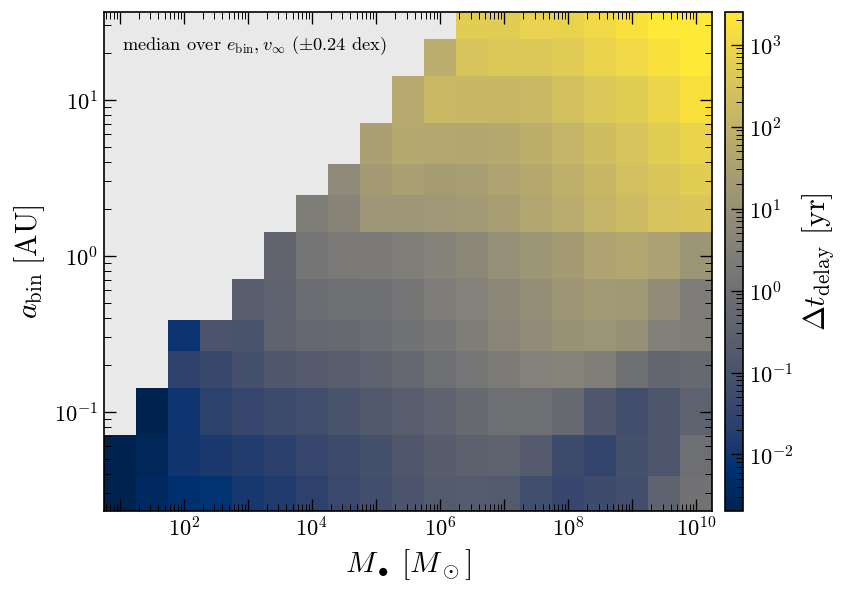

In [9]:
# ============ FIGURE: Dt_delay(M_bullet,a_bin) heatmap (median over e_bin, v_inf) ============
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
X_SYS=0.24                      # from the Dt_delay X-map (re-run gives the 1.989-corrected value)
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,Dt=c("M_smbh"),c("a_bin"),c("Dt_delay")
Mg,ag=np.unique(M),np.unique(a); good=np.isfinite(Dt)&(Dt>0)
Z=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        m=good&np.isclose(a,av)&np.isclose(M,Mv)
        if m.sum()>=5: Z[i,j]=np.median(Dt[m])
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,rf"median over $e_{{\rm bin}},v_\infty$ ($\pm{X_SYS:.2f}$ dex)",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_Ma.png",bbox_inches="tight"); fig.savefig("delay_Ma.pdf",bbox_inches="tight")
plt.show()

X(M,a): cells=151, median=0.196, 90th=0.802, max=1.535 dex


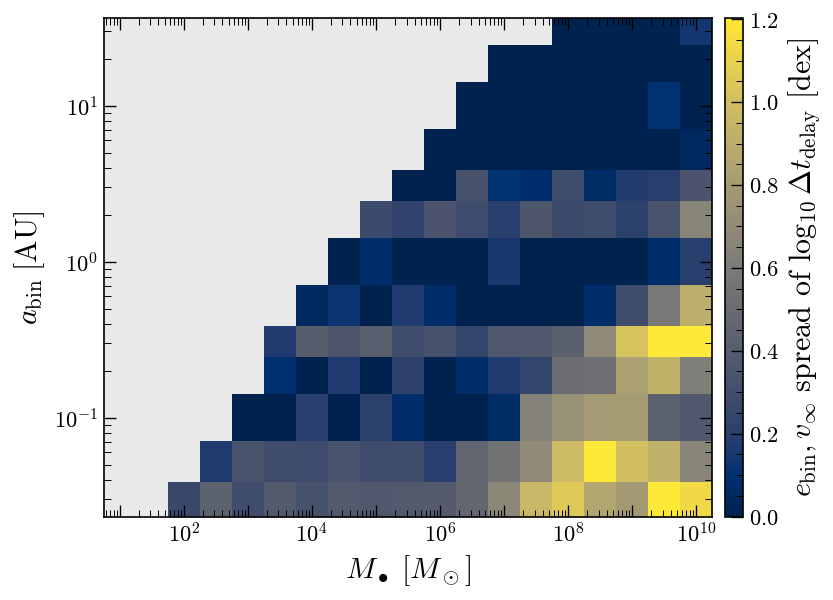

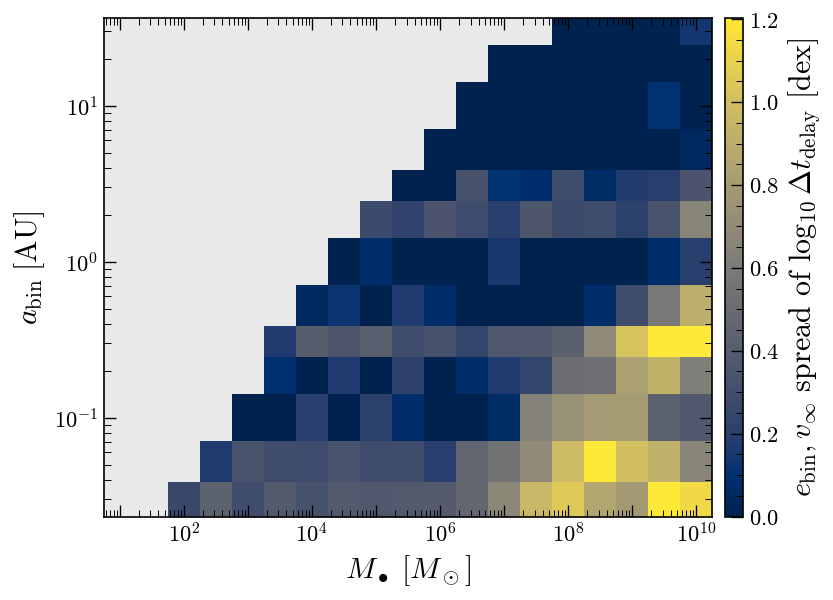

In [10]:
# ============ FIGURE: X(M_bullet,a_bin) = e_bin,v_inf spread of log10 Dt_delay (appendix) ============
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
MIN_CELL=5; MIN_SUB=20          # MIN_SUB: events per (e,v) sub-cell
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,fr,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
Mg,ag,eg,fg=np.unique(M),np.unique(a),np.unique(e),np.unique(fr)
good=np.isfinite(Dt)&(Dt>0)
XZ=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()<MIN_CELL: continue
        sub,se=[],[]
        for ev in eg:
            for fv in fg:
                m=base&np.isclose(e,ev)&np.isclose(fr,fv); n=m.sum()
                if n>=MIN_SUB:
                    ld=np.log10(Dt[m]); sub.append(np.median(ld)); se.append(1.253*np.std(ld)/np.sqrt(n))
        if len(sub)>=4:
            raw=np.percentile(sub,84)-np.percentile(sub,16)
            nf=1.989*np.sqrt(np.mean(np.square(se)))     # 16-84 width of the sampling noise
            XZ[i,j]=np.sqrt(max(raw**2-nf**2,0.0))
finite=XZ[np.isfinite(XZ)]
# ============ FIGURE: X(M_bullet,a_bin) = e_bin,v_inf spread of log10 Dt_delay (appendix) ============
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
MIN_CELL=5; MIN_SUB=20          # MIN_SUB: events per (e,v) sub-cell
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,fr,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
Mg,ag,eg,fg=np.unique(M),np.unique(a),np.unique(e),np.unique(fr)
good=np.isfinite(Dt)&(Dt>0)
XZ=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()<MIN_CELL: continue
        sub,se=[],[]
        for ev in eg:
            for fv in fg:
                m=base&np.isclose(e,ev)&np.isclose(fr,fv); n=m.sum()
                if n>=MIN_SUB:
                    ld=np.log10(Dt[m]); sub.append(np.median(ld)); se.append(1.253*np.std(ld)/np.sqrt(n))
        if len(sub)>=4:
            raw=np.percentile(sub,84)-np.percentile(sub,16)
            nf=1.989*np.sqrt(np.mean(np.square(se)))     # 16-84 width of the sampling noise
            XZ[i,j]=np.sqrt(max(raw**2-nf**2,0.0))
finite=XZ[np.isfinite(XZ)]
print("X(M,a): cells=%d" % finite.size + ((", median=%.3f, 90th=%.3f, max=%.3f dex" % (np.median(finite), np.percentile(finite,90), finite.max())) if finite.size else "  (insufficient statistics)"))

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(XZ),cmap=CIV,shading="flat",
                 vmin=0,vmax=(np.nanpercentile(XZ,98) if np.isfinite(XZ).any() else 1.0))
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$e_{\rm bin},v_\infty$ spread of $\log_{10}\Delta t_{\rm delay}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_Xmap.png",bbox_inches="tight"); fig.savefig("delay_Xmap.pdf",bbox_inches="tight")
plt.show()

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(XZ),cmap=CIV,shading="flat",
                 vmin=0,vmax=(np.nanpercentile(XZ,98) if np.isfinite(XZ).any() else 1.0))
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$e_{\rm bin},v_\infty$ spread of $\log_{10}\Delta t_{\rm delay}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_Xmap.png",bbox_inches="tight"); fig.savefig("delay_Xmap.pdf",bbox_inches="tight")
plt.show()

Dt_delay median over cells:  raw=0.324  noise=0.241  corrected X=0.196 dex


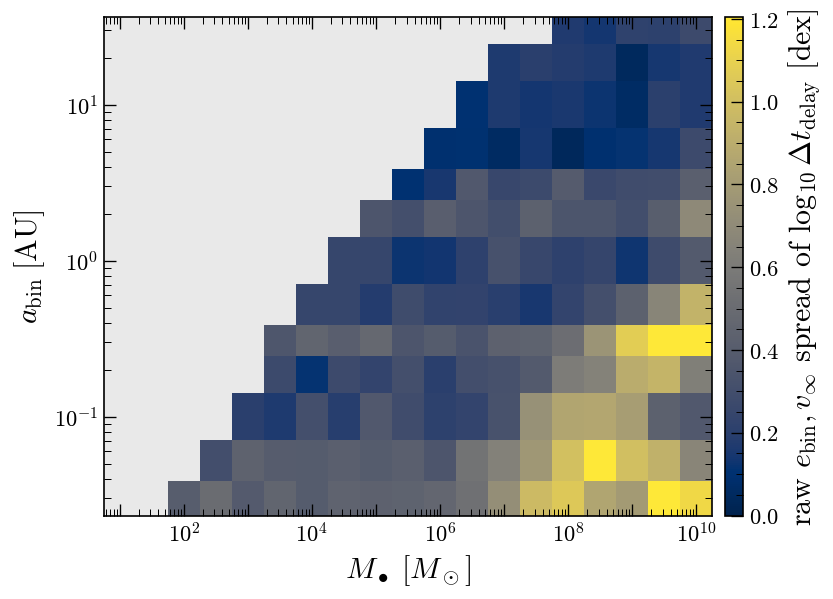

In [11]:
# ============ FIGURE: RAW X(M,a) = e,v spread of log10 Dt_delay (noise INCLUDED, not subtracted) ============
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
MIN_CELL=5; MIN_SUB=20
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,fr,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
Mg,ag,eg,fg=np.unique(M),np.unique(a),np.unique(e),np.unique(fr)
good=np.isfinite(Dt)&(Dt>0)
RAW=np.full((len(ag),len(Mg)),np.nan); raw_all=[]; nf_all=[]; cor_all=[]
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()<MIN_CELL: continue
        sub,se=[],[]
        for ev in eg:
            for fv in fg:
                m=base&np.isclose(e,ev)&np.isclose(fr,fv); n=m.sum()
                if n>=MIN_SUB:
                    ld=np.log10(Dt[m]); sub.append(np.median(ld)); se.append(1.253*np.std(ld)/np.sqrt(n))
        if len(sub)>=4:
            raw=np.percentile(sub,84)-np.percentile(sub,16)
            nf=1.989*np.sqrt(np.mean(np.square(se)))
            RAW[i,j]=raw                                    # <-- RAW (noise included)
            raw_all.append(raw); nf_all.append(nf); cor_all.append(np.sqrt(max(raw**2-nf**2,0.0)))
print(f"Dt_delay median over cells:  raw={np.median(raw_all):.3f}  noise={np.median(nf_all):.3f}  corrected X={np.median(cor_all):.3f} dex")

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(RAW),cmap=CIV,shading="flat",
                 vmin=0,vmax=(np.nanpercentile(RAW,98) if np.isfinite(RAW).any() else 1.0))
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"raw $e_{\rm bin},v_\infty$ spread of $\log_{10}\Delta t_{\rm delay}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_Xmap_raw.png",bbox_inches="tight"); fig.savefig("delay_Xmap_raw.pdf",bbox_inches="tight")
plt.show()

Dt_delay fit residual: median=0.299, 90th=0.784 dex


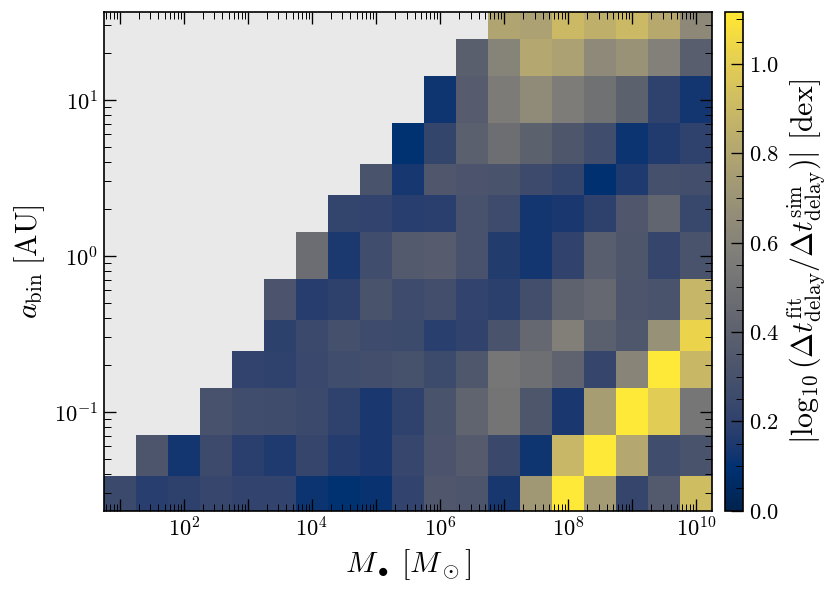

In [12]:
# ============ FIGURE: Dt_delay fit accuracy |log10(Dt_fit/Dt_sim)| on the (M,a) plane ============
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
good=np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)
# --- fit the semi-analytic (empirical) model: log10 Dt = poly(logM, loga, e, logv) ---
lM,la,lv=np.log10(M[good]),np.log10(a[good]),np.log10(frac[good]); ee=e[good]; y=np.log10(Dt[good])
Xd=np.column_stack([np.ones(good.sum()),lM,la,ee,ee**2,la**2,lM**2,lM*la,lv])
coef,*_=np.linalg.lstsq(Xd,y,rcond=None)
def model(M,a,e,frac):
    lM,la,lv=np.log10(M),np.log10(a),np.log10(frac)
    return coef@np.array([1,lM,la,e,e**2,la**2,lM**2,lM*la,lv])

Mg,ag,eg,fg=np.unique(M),np.unique(a),np.unique(e),np.unique(frac)
Z=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()<5: continue
        dd=[]
        for ev in eg:
            for fv in fg:
                m=base&np.isclose(e,ev)&np.isclose(frac,fv)
                if m.sum()>=5:
                    sim=np.median(np.log10(Dt[m]))          # sim (log10 Dt median)
                    fit=model(Mv,av,ev,fv)                  # semi-analytic fit
                    dd.append(abs(fit-sim))                 # |dex| residual
        if len(dd)>=4: Z[i,j]=np.median(dd)                 # median |dex| over e,v
print(f"Dt_delay fit residual: median={np.nanmedian(Z):.3f}, 90th={np.nanpercentile(Z,90):.3f} dex")

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,shading="flat",
                 vmin=0,vmax=np.nanpercentile(Z,98))
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$|\log_{10}(\Delta t_{\rm delay}^{\rm fit}/\Delta t_{\rm delay}^{\rm sim})|$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_residual.png",bbox_inches="tight"); fig.savefig("delay_residual.pdf",bbox_inches="tight")
plt.show()

SEMIANALYTIC_delay_heatmap OK


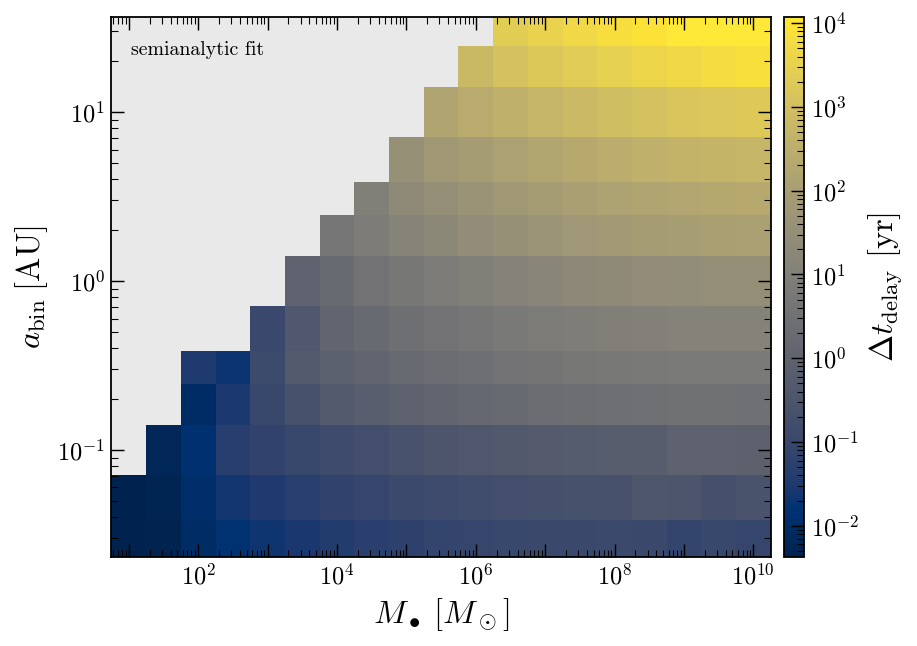

In [13]:
# ===== FIGURE: Dt_delay(M_bullet,a_bin) heatmap -- SEMI-ANALYTIC FORMULA (not sim median) =====
# Same grid/marginalization as the simulation figure (median over the e_bin, v_inf events
# in each (M,a) cell), but coloured by the semi-analytic delay fit
#   log10 Dt = coef . [1, lM, la, e, e^2, la^2, lM^2, lM*la, lv]
# (the same empirical model used for the fit-residual figure), evaluated at each event.
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
def edges(c):
    c=np.log10(np.asarray(c,float)); e=np.empty(c.size+1)
    e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-(c[1]-c[0])/2; e[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**e
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
good=np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)

# --- fit the semi-analytic model (same as the residual figure) ---
lM,la,lv=np.log10(M[good]),np.log10(a[good]),np.log10(frac[good]); ee=e[good]; y=np.log10(Dt[good])
Xd=np.column_stack([np.ones(good.sum()),lM,la,ee,ee**2,la**2,lM**2,lM*la,lv])
coef,*_=np.linalg.lstsq(Xd,y,rcond=None)
def model(M,a,e,frac):                                        # vectorized -> log10 Dt/yr
    lM,la,lv=np.log10(M),np.log10(a),np.log10(frac)
    X=np.column_stack([np.ones_like(lM),lM,la,e,e**2,la**2,lM**2,lM*la,lv])
    return X@coef

Mg,ag=np.unique(M),np.unique(a)
Z=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)          # same populated cells as the sim
        if base.sum()>=5:                                    # median over the e_bin, v_inf events
            Z[i,j]=np.median(10**model(M[base],a[base],e[base],frac[base]))
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({
    "figure.dpi":130,"savefig.dpi":220,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")
ax.set_xscale("log"); ax.set_yscale("log")
# major x-ticks every decade (labels only every 2 decades via _even_pow), minor ticks 2-9
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=100)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,r"semianalytic fit",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("delay_heatmap_fit.png",bbox_inches="tight"); fig.savefig("delay_heatmap_fit.pdf",bbox_inches="tight")
print("SEMIANALYTIC_delay_heatmap OK")

SMOOTH_delay_heatmap OK


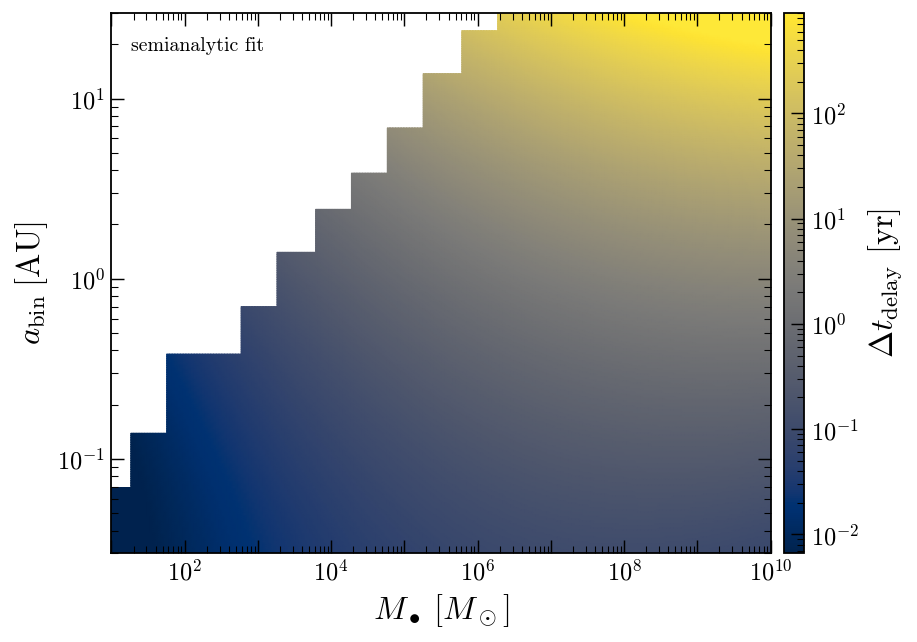

In [14]:
# ===== FIGURE: Dt_delay(M_bullet,a_bin) SMOOTH semi-analytic heatmap (fine grid) =====
# Semi-analytic delay fit  log10 Dt = coef.[1,lM,la,e,e^2,la^2,lM^2,lM*la,lv]  (same model
# as the residual/binned figures), evaluated on a fine (M,a) grid and marginalised over
# e_bin and v_inf (median of 10^model over an e- and frac-grid). Masked to the EXACT
# simulated footprint (the binned populated (M,a) cells, via nearest-bin), so the exclusion
# domain matches the numerical figure instead of an approximate analytic cut.
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""
def edges(cc):                           # log-cell edges for the binned grid
    cc=np.log10(np.asarray(cc,float)); ee=np.empty(cc.size+1)
    ee[1:-1]=0.5*(cc[:-1]+cc[1:]); ee[0]=cc[0]-(cc[1]-cc[0])/2; ee[-1]=cc[-1]+(cc[-1]-cc[-2])/2
    return 10**ee

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
good=np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)

# --- exact simulated footprint: which binned (M,a) cells have data (>=5 events) ---
Mb,ab=np.unique(M),np.unique(a)
pop=np.zeros((len(ab),len(Mb)),bool)
for i,av in enumerate(ab):
    for j,Mv in enumerate(Mb):
        pop[i,j]=(good&np.isclose(a,av)&np.isclose(M,Mv)).sum()>=5
Medg,aedg=edges(Mb),edges(ab)

# --- fit the semi-analytic model (same as the residual figure) ---
lM,la,lv=np.log10(M[good]),np.log10(a[good]),np.log10(frac[good]); ee=e[good]; y=np.log10(Dt[good])
Xd=np.column_stack([np.ones(good.sum()),lM,la,ee,ee**2,la**2,lM**2,lM*la,lv])
coef,*_=np.linalg.lstsq(Xd,y,rcond=None)
def model(M,a,e,frac):                                   # vectorized -> log10 Dt/yr
    lM,la,lv=np.log10(M),np.log10(a),np.log10(frac)
    X=np.column_stack([np.ones_like(lM),lM,la,e,e**2,la**2,lM**2,lM*la,lv]); return X@coef

# ---- fine plotted grid + marginalisation grids ----
NM,NAx=240,240
MF=np.logspace(1,10,NM)                               # M_bullet [Msun]
AF=np.logspace(np.log10(0.03),np.log10(30.0),NAx)     # a_bin [AU]
Em=np.linspace(0.0,0.99,13); Fm=np.logspace(-3,1,13)  # marginalise e_bin, v_inf
EE,FF=np.meshgrid(Em,Fm); er,fr=EE.ravel(),FF.ravel()

# map each fine point to its binned cell, keep only cells in the simulated footprint
jx=np.clip(np.digitize(MF,Medg)-1,0,len(Mb)-1)
iy=np.clip(np.digitize(AF,aedg)-1,0,len(ab)-1)
Z=np.full((NAx,NM),np.nan)
for i,av in enumerate(AF):
    for j,Mv in enumerate(MF):
        if not pop[iy[i],jx[j]]: continue             # outside the simulated footprint
        Z[i,j]=np.median(10**model(np.full(er.size,Mv),np.full(er.size,av),er,fr))
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({
    "figure.dpi":130,"savefig.dpi":220,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(MF,AF,np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="gouraud")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(MF[0],MF[-1]); ax.set_ylim(AF[0],AF[-1])
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=100)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,r"semianalytic fit",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("delay_heatmap_smooth.png",bbox_inches="tight"); fig.savefig("delay_heatmap_smooth.pdf",bbox_inches="tight")
print("SMOOTH_delay_heatmap OK")

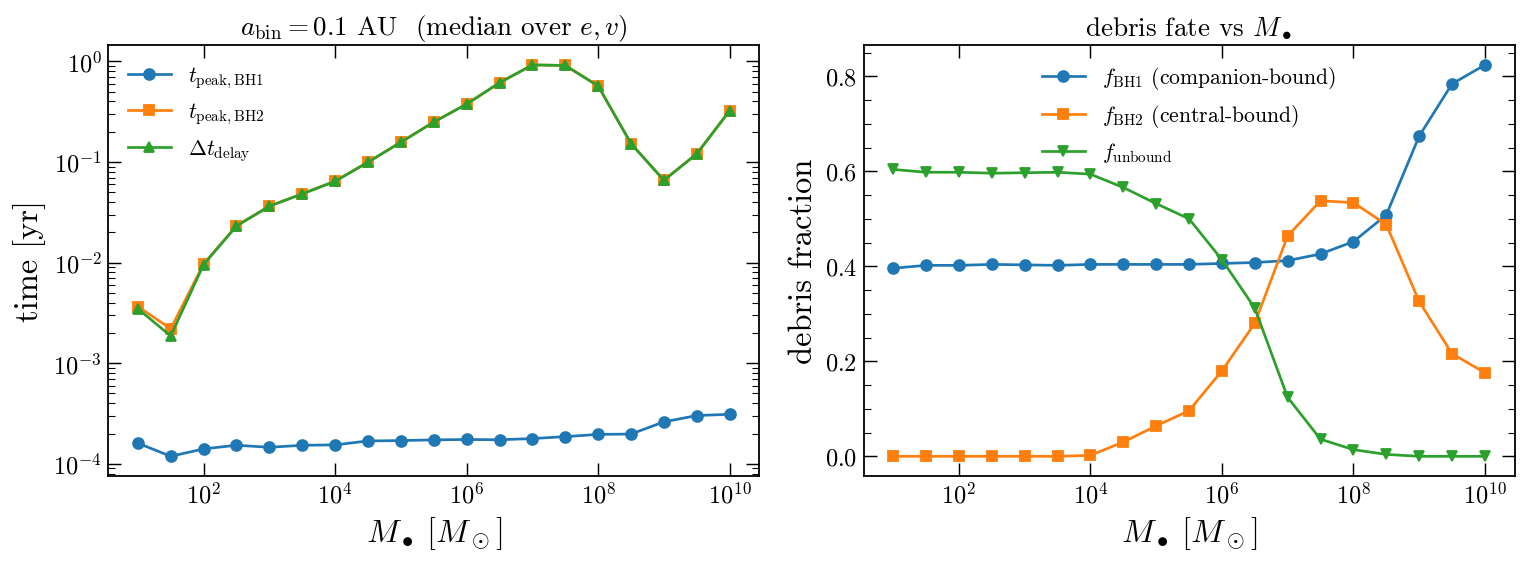

In [15]:
import numpy as np, csv
import matplotlib.pyplot as plt
r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); col=lambda k:np.array([float(x[k]) for x in r])
M,a   = col("M_smbh"), col("a_bin")
t1,t2 = col("t_peak_BH1"), col("t_peak_BH2"); Dt=col("Dt_delay")
fB1,fB2 = col("f_BH1"), col("f_BH2")

anode = np.unique(a)[np.argmin(np.abs(np.unique(a)-0.08))]   # a-node nearest 0.08 AU
sel   = np.isclose(a, anode)
Mn    = np.unique(M[sel])
def med(x, good):
    return np.array([np.median(x[sel & np.isclose(M,m) & good]) if (sel & np.isclose(M,m) & good).any()
                     else np.nan for m in Mn])
gt = np.isfinite(t1)&np.isfinite(t2)&(t1>0)&(t2>0)
gD = np.isfinite(Dt)&(Dt>0)
mt1,mt2,mDt = med(t1,gt), med(t2,gt), med(Dt,gD)
mf1,mf2     = med(fB1,np.isfinite(fB1)), med(fB2,np.isfinite(fB2))

fig,ax=plt.subplots(1,2,figsize=(12,4.6))
ax[0].plot(Mn,mt1,"o-",label=r"$t_{\rm peak,BH1}$")
ax[0].plot(Mn,mt2,"s-",label=r"$t_{\rm peak,BH2}$")
ax[0].plot(Mn,mDt,"^-",label=r"$\Delta t_{\rm delay}$")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[0].set_ylabel("time [yr]")
ax[0].set_title(rf"$a_{{\rm bin}}={anode:.3g}$ AU  (median over $e,v$)"); ax[0].legend(frameon=False)
ax[1].plot(Mn,mf1,"o-",label=r"$f_{\rm BH1}$ (companion-bound)")
ax[1].plot(Mn,mf2,"s-",label=r"$f_{\rm BH2}$ (central-bound)")
ax[1].plot(Mn,1-mf1-mf2,"v-",label=r"$f_{\rm unbound}$")
ax[1].set_xscale("log"); ax[1].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[1].set_ylabel("debris fraction")
ax[1].set_title("debris fate vs $M_\\bullet$"); ax[1].legend(frameon=False)
fig.tight_layout(); plt.show()

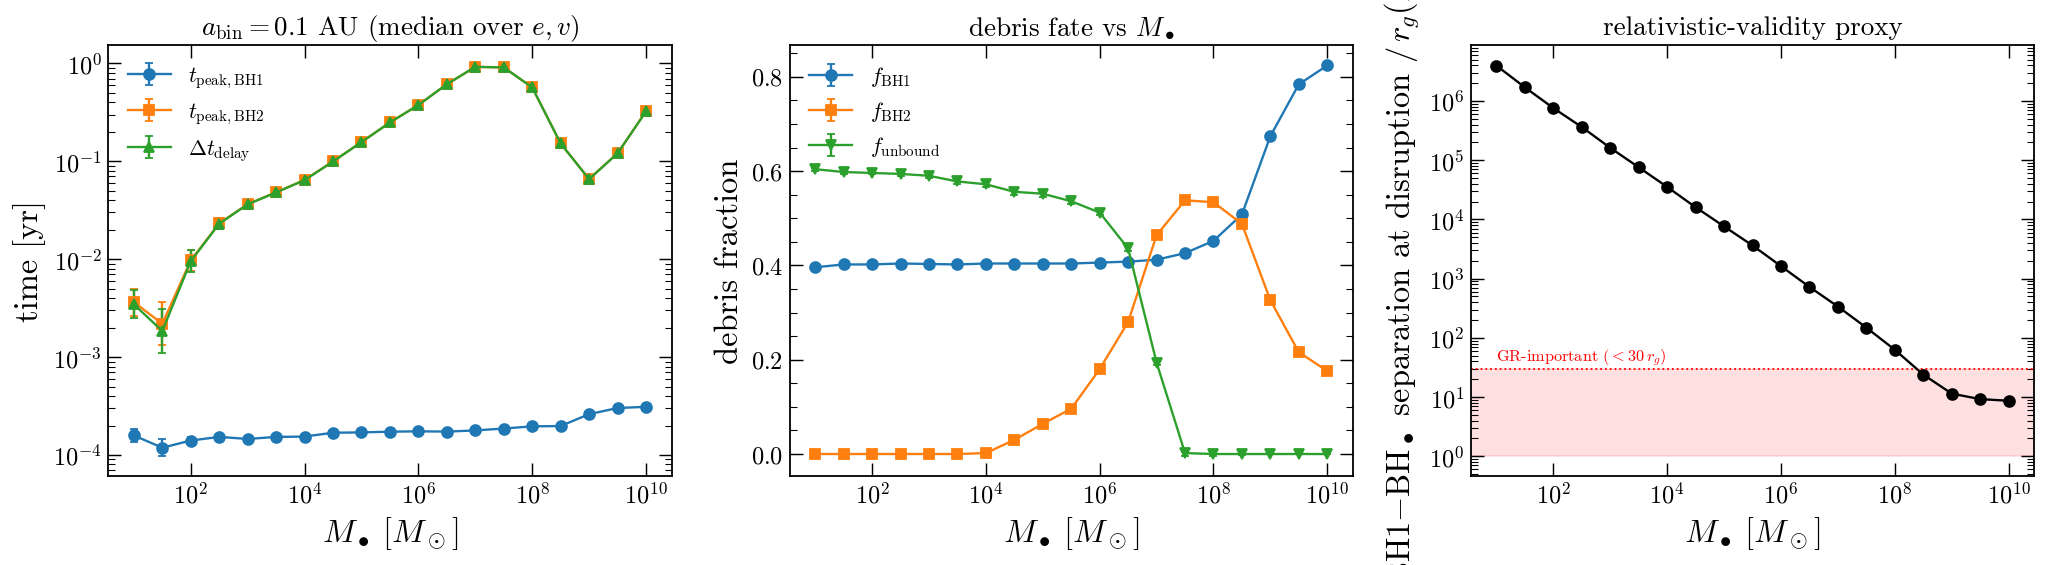

In [16]:
import numpy as np, csv, os, h5py
import matplotlib.pyplot as plt

# --- timing + fates from the delay table (mu-TDE order) ---
r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); col=lambda k:np.array([float(x[k]) for x in r])
M,a   = col("M_smbh"), col("a_bin")
t1,t2 = col("t_peak_BH1"), col("t_peak_BH2"); Dt=col("Dt_delay")
fB1,fB2,fU = col("f_BH1"), col("f_BH2"), col("f_unb")

# --- relativistic-validity proxy: BH1-BH_bullet separation at disruption, in r_g(M_bullet) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; oc=R["outcome"].asstr()[:]; mu=np.where(oc=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]                       # fancy-index only the mu-TDE rows (mu is sorted)
    d=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) and bundle mu-TDE ({len(mu)}) counts differ"
RG   = (29.7847/299792.458)**2 * M             # r_g(M_bullet) in AU
d_rg = d/RG                                     # disruption depth in gravitational radii

anode=np.unique(a)[np.argmin(np.abs(np.unique(a)-0.1))]
sel=np.isclose(a,anode); Mn=np.unique(M[sel])

def med_log(x, good):                           # median + SE-of-median, asymmetric on a log axis
    out=[]
    for m in Mn:
        s=sel&np.isclose(M,m)&good&(x>0)&np.isfinite(x); n=s.sum()
        if n: l=np.log10(x[s]); c=np.median(l); se=1.2533*np.std(l)/np.sqrt(n); out.append((10**c,10**c-10**(c-se),10**(c+se)-10**c))
        else: out.append((np.nan,np.nan,np.nan))
    o=np.array(out); return o[:,0],o[:,1],o[:,2]
def med_lin(x, good):
    out=[]
    for m in Mn:
        s=sel&np.isclose(M,m)&good&np.isfinite(x); n=s.sum()
        if n: out.append((np.median(x[s]),1.2533*np.std(x[s])/np.sqrt(n)))
        else: out.append((np.nan,np.nan))
    o=np.array(out); return o[:,0],o[:,1]

gt=np.isfinite(t1)&np.isfinite(t2)&(t1>0)&(t2>0); gD=np.isfinite(Dt)&(Dt>0)
T1,T2,DT = med_log(t1,gt), med_log(t2,gt), med_log(Dt,gD)
F1,F2,FU = med_lin(fB1,np.isfinite(fB1)), med_lin(fB2,np.isfinite(fB2)), med_lin(fU,np.isfinite(fU))
DRG      = med_log(d_rg, np.isfinite(d_rg))

fig,ax=plt.subplots(1,3,figsize=(16,4.6))
for (y,lo,hi),lab,mk in [(T1,r"$t_{\rm peak,BH1}$","o"),(T2,r"$t_{\rm peak,BH2}$","s"),(DT,r"$\Delta t_{\rm delay}$","^")]:
    ax[0].errorbar(Mn,y,yerr=[lo,hi],fmt=mk+"-",capsize=2,lw=1.3,label=lab)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[0].set_ylabel("time [yr]")
ax[0].set_title(rf"$a_{{\rm bin}}={anode:.3g}$ AU (median over $e,v$)"); ax[0].legend(frameon=False)

for (y,se),lab,mk in [(F1,r"$f_{\rm BH1}$","o"),(F2,r"$f_{\rm BH2}$","s"),(FU,r"$f_{\rm unbound}$","v")]:
    ax[1].errorbar(Mn,y,yerr=se,fmt=mk+"-",capsize=2,lw=1.3,label=lab)
ax[1].set_xscale("log"); ax[1].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[1].set_ylabel("debris fraction")
ax[1].set_title("debris fate vs $M_\\bullet$"); ax[1].legend(frameon=False)

y,lo,hi=DRG
ax[2].errorbar(Mn,y,yerr=[lo,hi],fmt="o-",color="k",capsize=2,lw=1.3)
ax[2].axhspan(1,30,color="red",alpha=0.12); ax[2].axhline(30,color="red",ls=":",lw=1)
ax[2].text(Mn[0],32,"GR-important ($<30\\,r_g$)",color="red",fontsize=9,va="bottom")
ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[2].set_ylabel(r"BH1$-$BH$_\bullet$ separation at disruption $/\,r_g(M_\bullet)$")
ax[2].set_title("relativistic-validity proxy")
fig.tight_layout(); plt.show()

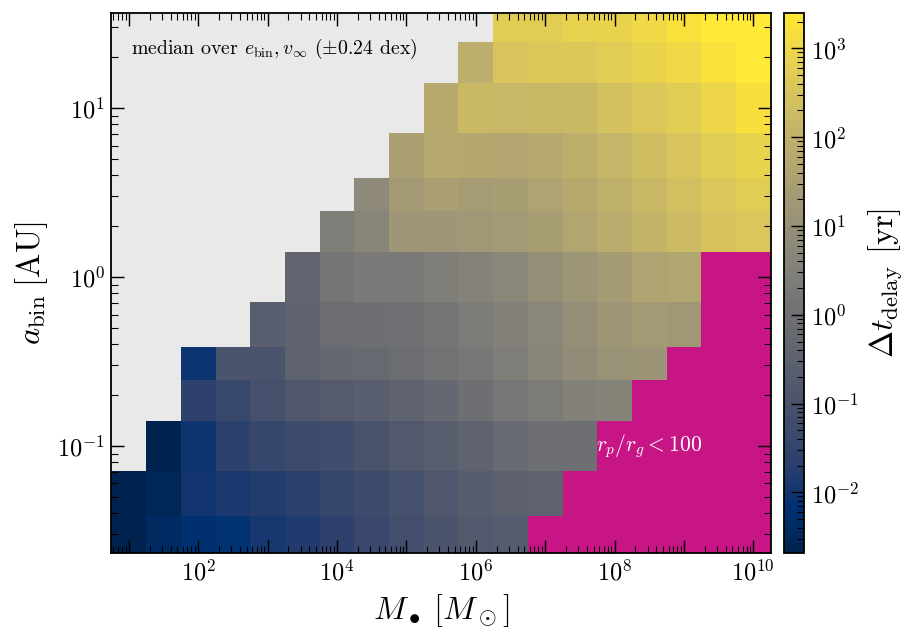

In [17]:
# ===== FIGURE: Dt_delay(M_bullet, a_bin) heatmap + relativistic-validity mask (r_p/r_g < RG_MIN) =====
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
X_SYS=0.24
RG_MIN=100.0     # mask cells whose median pericenter is < RG_MIN r_g (PN corr ~ r_p/r_g:
                # 100->1%, 30->3%, 10->10%, ISCO~6; below ~8 r_g debris plunge, no fallback)
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

# --- Dt_delay from the delay table (one level up) ---
r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,Dt=c("M_smbh"),c("a_bin"),c("Dt_delay")

# --- pericenter depth r_p/r_g from the bundle (one level up; same mu-TDE order as the CSV) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)      # r_g(M_bullet)=(V1/c)^2 M  [AU]

Mg,ag=np.unique(M),np.unique(a); good=np.isfinite(Dt)&(Dt>0)
Z  =np.full((len(ag),len(Mg)),np.nan)       # median Dt_delay
RPG=np.full((len(ag),len(Mg)),np.nan)       # median r_p/r_g
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        m=good&np.isclose(a,av)&np.isclose(M,Mv)
        if m.sum()>=5: Z[i,j]=np.median(Dt[m])
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")

# --- mask the relativistic cells (populated AND r_p/r_g < RG_MIN) ---
blk=np.full_like(Z,np.nan); blk[np.isfinite(Z)&np.isfinite(RPG)&(RPG<RG_MIN)]=1.0
ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mg[bj].min())+np.log10(Mg[bj].max())))   # log-midpoint of the M-range
    at=10**(np.median(np.log10(ag[bi])))                            # median a of masked cells
    ax.text(Mt,at,rf"$r_p/r_g<{int(RG_MIN)}$",color="white",ha="center",va="center",
            fontsize=12,fontweight="bold")

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,rf"median over $e_{{\rm bin}},v_\infty$ ($\pm{X_SYS:.2f}$ dex)",
        transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("delay_Ma_validity.png",bbox_inches="tight"); fig.savefig("delay_Ma_validity.pdf",bbox_inches="tight")
plt.show()

X(M,a): cells=151, median=0.196, 90th=0.802, max=1.535 dex


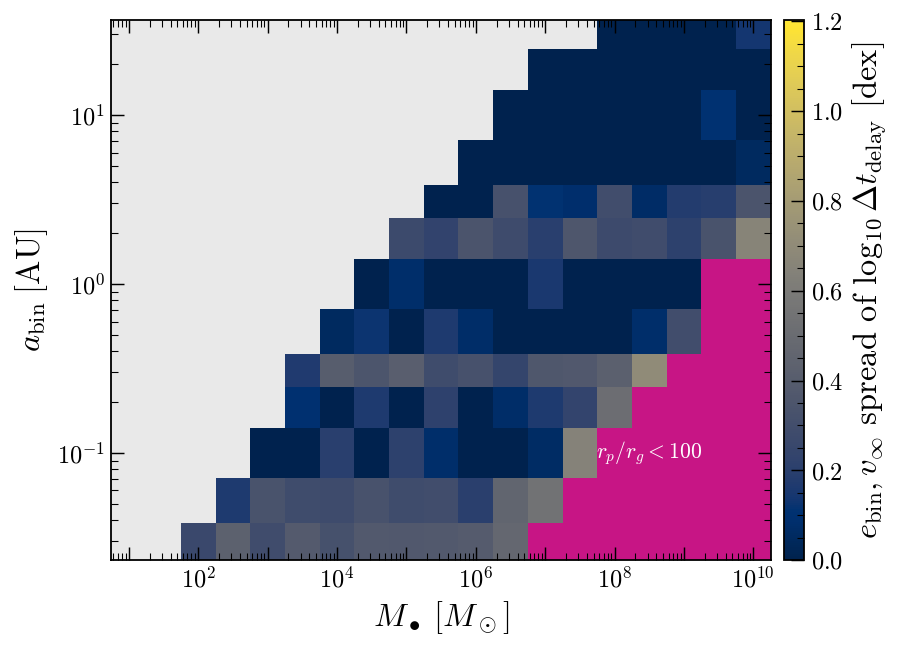

In [18]:
# ============ FIGURE: X(M_bullet,a_bin) = e_bin,v_inf spread of log10 Dt_delay (appendix) + validity mask ============
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
MIN_CELL=5; MIN_SUB=20          # MIN_SUB: events per (e,v) sub-cell
RG_MIN=100.0                     # mask cells whose median pericenter is < RG_MIN r_g
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

# --- spread X(M,a) from the delay table (one level up) ---
r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,fr,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
Mg,ag,eg,fg=np.unique(M),np.unique(a),np.unique(e),np.unique(fr)
good=np.isfinite(Dt)&(Dt>0)
XZ=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()<MIN_CELL: continue
        sub,se=[],[]
        for ev in eg:
            for fv in fg:
                m=base&np.isclose(e,ev)&np.isclose(fr,fv); n=m.sum()
                if n>=MIN_SUB:
                    ld=np.log10(Dt[m]); sub.append(np.median(ld)); se.append(1.253*np.std(ld)/np.sqrt(n))
        if len(sub)>=4:
            raw=np.percentile(sub,84)-np.percentile(sub,16)
            nf=1.989*np.sqrt(np.mean(np.square(se)))     # 16-84 width of the sampling noise
            XZ[i,j]=np.sqrt(max(raw**2-nf**2,0.0))
finite=XZ[np.isfinite(XZ)]
print("X(M,a): cells=%d" % finite.size + ((", median=%.3f, 90th=%.3f, max=%.3f dex" % (np.median(finite), np.percentile(finite,90), finite.max())) if finite.size else "  (insufficient statistics)"))

# --- pericenter depth r_p/r_g per (M,a) cell from the bundle (one level up; mu-TDE order) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)
RPG=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(XZ),cmap=CIV,shading="flat",
                 vmin=0,vmax=(np.nanpercentile(XZ,98) if np.isfinite(XZ).any() else 1.0))

# --- mask the relativistic cells (populated AND r_p/r_g < RG_MIN) ---
blk=np.full_like(XZ,np.nan); blk[np.isfinite(XZ)&np.isfinite(RPG)&(RPG<RG_MIN)]=1.0
ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mg[bj].min())+np.log10(Mg[bj].max())))
    at=10**(np.median(np.log10(ag[bi])))
    ax.text(Mt,at,rf"$r_p/r_g<{int(RG_MIN)}$",color="white",ha="center",va="center",
            fontsize=12,fontweight="bold")

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$e_{\rm bin},v_\infty$ spread of $\log_{10}\Delta t_{\rm delay}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_Xmap.png",bbox_inches="tight"); fig.savefig("delay_Xmap.pdf",bbox_inches="tight")
plt.show()

Dt_delay median over cells:  raw=0.324  noise=0.241  corrected X=0.196 dex


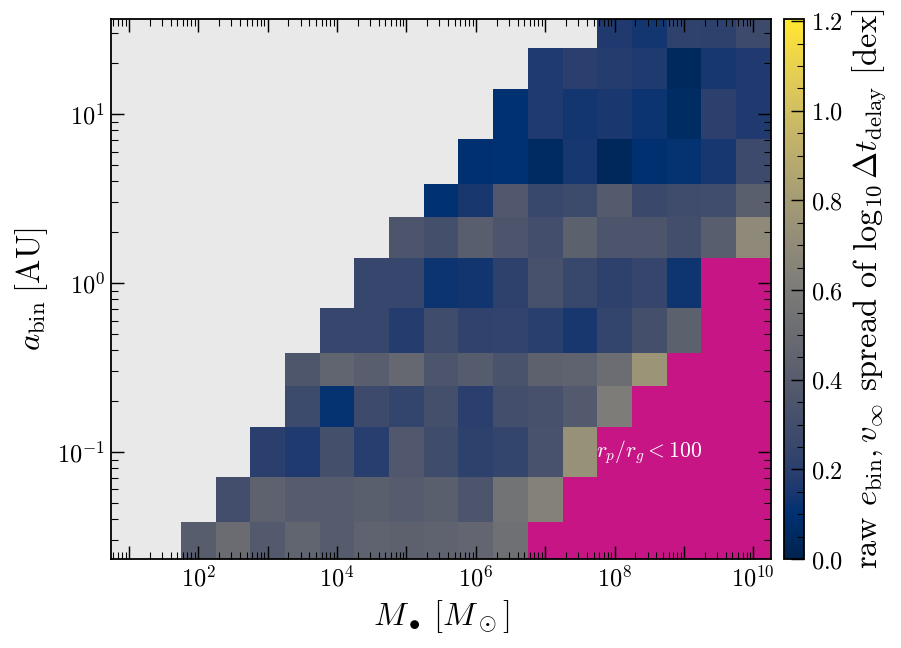

In [19]:
# ============ FIGURE: RAW X(M,a) = e,v spread of log10 Dt_delay (noise INCLUDED) + validity mask ============
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
MIN_CELL=5; MIN_SUB=20
RG_MIN=100.0                     # mask cells whose median pericenter is < RG_MIN r_g
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,fr,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
Mg,ag,eg,fg=np.unique(M),np.unique(a),np.unique(e),np.unique(fr)
good=np.isfinite(Dt)&(Dt>0)
RAW=np.full((len(ag),len(Mg)),np.nan); raw_all=[]; nf_all=[]; cor_all=[]
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()<MIN_CELL: continue
        sub,se=[],[]
        for ev in eg:
            for fv in fg:
                m=base&np.isclose(e,ev)&np.isclose(fr,fv); n=m.sum()
                if n>=MIN_SUB:
                    ld=np.log10(Dt[m]); sub.append(np.median(ld)); se.append(1.253*np.std(ld)/np.sqrt(n))
        if len(sub)>=4:
            raw=np.percentile(sub,84)-np.percentile(sub,16)
            nf=1.989*np.sqrt(np.mean(np.square(se)))
            RAW[i,j]=raw                                    # <-- RAW (noise included)
            raw_all.append(raw); nf_all.append(nf); cor_all.append(np.sqrt(max(raw**2-nf**2,0.0)))
print(f"Dt_delay median over cells:  raw={np.median(raw_all):.3f}  noise={np.median(nf_all):.3f}  corrected X={np.median(cor_all):.3f} dex")

# --- pericenter depth r_p/r_g per (M,a) cell from the bundle (one level up; mu-TDE order) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)
RPG=np.full((len(ag),len(Mg)),np.nan)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(RAW),cmap=CIV,shading="flat",
                 vmin=0,vmax=(np.nanpercentile(RAW,98) if np.isfinite(RAW).any() else 1.0))

# --- mask the relativistic cells (populated AND r_p/r_g < RG_MIN) ---
blk=np.full_like(RAW,np.nan); blk[np.isfinite(RAW)&np.isfinite(RPG)&(RPG<RG_MIN)]=1.0
ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mg[bj].min())+np.log10(Mg[bj].max())))
    at=10**(np.median(np.log10(ag[bi])))
    ax.text(Mt,at,rf"$r_p/r_g<{int(RG_MIN)}$",color="white",ha="center",va="center",
            fontsize=12,fontweight="bold")

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"raw $e_{\rm bin},v_\infty$ spread of $\log_{10}\Delta t_{\rm delay}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_Xmap_raw.png",bbox_inches="tight"); fig.savefig("delay_Xmap_raw.pdf",bbox_inches="tight")
plt.show()

In [1]:
# ===== DELAY FIT (paper): coefficients, accuracy, scatter; with and without e_bin =====
# Fit on the trustworthy events only (pericenter r_p >= RG_MIN r_g; deeper encounters need GR).
#   (M,a) fit :  log10(Dt/yr) = d0 + d1 xM + d2 xa + d3 xM^2 + d4 xa^2 + d5 xM xa
#   (M,a,e)   :  same + d6 e + d7 e^2          xM=log10(M_bullet/Msun), xa=log10(a_bin/AU)
# (a v_inf term was tested and dropped: coefficient ~0.003, no change in R^2)
import numpy as np, csv, os, h5py
RG_MIN=100.0
r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("Dt_delay")
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)
trust=np.isfinite(Dt)&(Dt>0)&(rp_rg>=RG_MIN)
xM,xa,ee,y=np.log10(M[trust]),np.log10(a[trust]),e[trust],np.log10(Dt[trust])
X2=np.column_stack([np.ones_like(xM),xM,xa,xM**2,xa**2,xM*xa]); X3=np.column_stack([X2,ee,ee**2])
fits={}
for name,X,lab in (("Ma",X2,"d0..d5"),("Mae",X3,"d0..d7")):
    cf,*_=np.linalg.lstsq(X,y,rcond=None); res=y-X@cf; fits[name]=(cf,res)
    print(f"{name:4s} {lab}: "+", ".join(f"{v:+.4f}" for v in cf))
    print(f"      R^2={1-res.var()/y.var():.4f}  residual std={res.std():.3f} dex  "
          f"(16-84% half-width {(np.percentile(res,84)-np.percentile(res,16))/2:.3f})")
r2,r3=fits["Ma"][1],fits["Mae"][1]
print(f"N={trust.sum()} events with r_p>={RG_MIN:.0f} r_g;  adding e: residual variance -{(1-r3.var()/r2.var())*100:.1f}%, "
      f"R^2 +{100*(r2.var()-r3.var())/y.var():.2f} points, rms -{(1-r3.std()/r2.std())*100:.1f}%")


Ma   d0..d5: +0.2511, -0.1181, +2.0696, +0.0353, +0.1251, -0.1473
      R^2=0.8042  residual std=0.682 dex  (16-84% half-width 0.653)
Mae  d0..d7: -0.3275, -0.1151, +1.8921, +0.0345, +0.2131, -0.1421, +0.0114, +0.6774
      R^2=0.8114  residual std=0.669 dex  (16-84% half-width 0.642)
N=219087 events with r_p>=100 r_g;  adding e: residual variance -3.7%, R^2 +0.72 points, rms -1.9%


Dt_delay fit residual (r_p>=100 r_g cells): median=0.138, 90th=0.378, max=1.309 dex


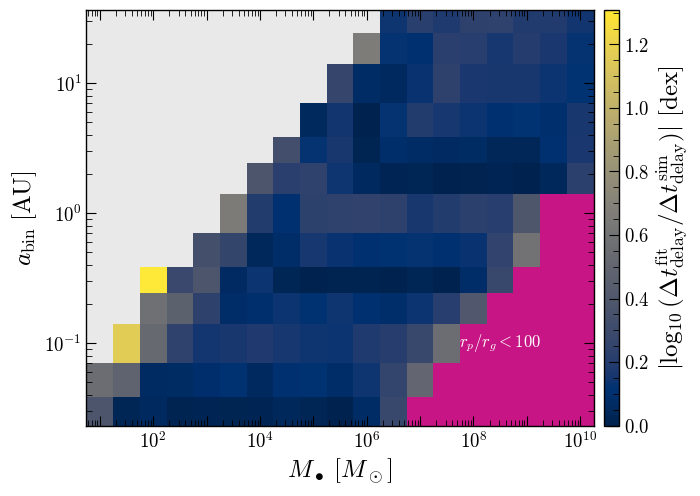

In [1]:
# ============ FIGURE: Dt_delay fit accuracy |log10(Dt_fit/Dt_sim)| on the (M,a) plane + validity mask ============
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
RG_MIN=100.0                     # mask cells (and exclude from the fit) with median pericenter < RG_MIN r_g
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")

# --- pericenter depth r_p/r_g per event from the bundle (one level up; mu-TDE order) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)

good =np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)
trust=good&(rp_rg>=RG_MIN)      # fit only on the trustworthy (non-relativistic) events
# --- Dt_delay fit (paper): log10(Dt/yr) = d0 + d1 xM + d2 xa + d3 xM^2 + d4 xa^2 + d5 xM xa,
#     xM=log10(M_bullet/Msun), xa=log10(a_bin/AU); least squares on `trust` (see the DELAY FIT cell)
xM,xa=np.log10(M[trust]),np.log10(a[trust]); y=np.log10(Dt[trust])
coef,*_=np.linalg.lstsq(np.column_stack([np.ones_like(xM),xM,xa,xM**2,xa**2,xM*xa]),y,rcond=None)
def model(M,a):                                          # -> log10(Dt/yr), vectorized
    xM,xa=np.log10(M),np.log10(a)
    return coef[0]+coef[1]*xM+coef[2]*xa+coef[3]*xM**2+coef[4]*xa**2+coef[5]*xM*xa
Mg,ag=np.unique(M),np.unique(a)
Z=np.full((len(ag),len(Mg)),np.nan)      # |fit - sim| per (M,a) cell [dex]
RPG=np.full((len(ag),len(Mg)),np.nan)    # median r_p/r_g (for the mask)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)
        if base.sum()>=5:                                  # sim = median log10 Dt over the cell's (e_bin, v_inf) events
            Z[i,j]=abs(model(Mv,av)-np.median(np.log10(Dt[base])))
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])
ok=np.isfinite(Z)&np.isfinite(RPG)&(RPG>=RG_MIN)
print(f"Dt_delay fit residual (r_p>={RG_MIN:.0f} r_g cells): median={np.nanmedian(Z[ok]):.3f}, 90th={np.nanpercentile(Z[ok],90):.3f}, max={np.nanmax(Z[ok]):.3f} dex")

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,shading="flat",
                 vmin=0,vmax=np.nanmax(Z[ok]))   # colour range set by the unmasked cells

# --- mask the relativistic cells (populated AND r_p/r_g < RG_MIN) ---
blk=np.full_like(Z,np.nan); blk[np.isfinite(Z)&np.isfinite(RPG)&(RPG<RG_MIN)]=1.0
ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mg[bj].min())+np.log10(Mg[bj].max())))
    at=10**(np.median(np.log10(ag[bi])))
    ax.text(Mt,at,rf"$r_p/r_g<{int(RG_MIN)}$",color="white",ha="center",va="center",
            fontsize=12,fontweight="bold")

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015, pos.y0, 0.022, pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$|\log_{10}(\Delta t_{\rm delay}^{\rm fit}/\Delta t_{\rm delay}^{\rm sim})|$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
for t in list(ax.xaxis.get_major_ticks())+list(ax.xaxis.get_minor_ticks()):
    t.tick1line.set_color("white"); t.tick2line.set_color("black")
fig.savefig("delay_residual.png",bbox_inches="tight"); fig.savefig("delay_residual.pdf",bbox_inches="tight")
plt.show()

SEMIANALYTIC_delay_heatmap OK


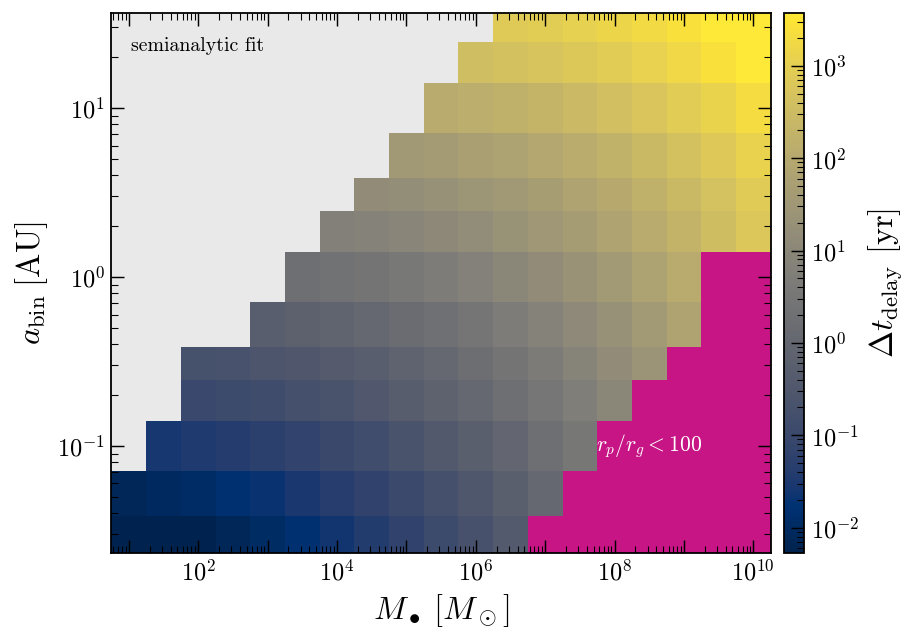

In [3]:
# ===== FIGURE: Dt_delay(M_bullet,a_bin) heatmap -- SEMI-ANALYTIC FORMULA (not sim median) + validity mask =====
# Same (M,a) cells as the simulation figure, coloured by the (M,a) delay fit
#   log10 Dt = d0 + d1 xM + d2 xa + d3 xM^2 + d4 xa^2 + d5 xM xa   (fit on r_p >= RG_MIN r_g events)
# evaluated at the cell centre (same fit as the residual figure).
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
RG_MIN=100.0                     # mask cells (and exclude from the fit) with median pericenter < RG_MIN r_g
def edges(c):
    c=np.log10(np.asarray(c,float)); e=np.empty(c.size+1)
    e[1:-1]=0.5*(c[:-1]+c[1:]); e[0]=c[0]-(c[1]-c[0])/2; e[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**e
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")

# --- pericenter depth r_p/r_g per event from the bundle (one level up; mu-TDE order) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)

good =np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)
trust=good&(rp_rg>=RG_MIN)      # fit only on the trustworthy (non-relativistic) events
# --- Dt_delay fit (paper): log10(Dt/yr) = d0 + d1 xM + d2 xa + d3 xM^2 + d4 xa^2 + d5 xM xa,
#     xM=log10(M_bullet/Msun), xa=log10(a_bin/AU); least squares on `trust` (see the DELAY FIT cell)
xM,xa=np.log10(M[trust]),np.log10(a[trust]); y=np.log10(Dt[trust])
coef,*_=np.linalg.lstsq(np.column_stack([np.ones_like(xM),xM,xa,xM**2,xa**2,xM*xa]),y,rcond=None)
def model(M,a):                                          # -> log10(Dt/yr), vectorized
    xM,xa=np.log10(M),np.log10(a)
    return coef[0]+coef[1]*xM+coef[2]*xa+coef[3]*xM**2+coef[4]*xa**2+coef[5]*xM*xa
Mg,ag=np.unique(M),np.unique(a)
Z=np.full((len(ag),len(Mg)),np.nan)       # semi-analytic median Dt
RPG=np.full((len(ag),len(Mg)),np.nan)     # median r_p/r_g (for the mask)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        base=good&np.isclose(a,av)&np.isclose(M,Mv)          # same populated cells as the sim
        if base.sum()>=5:
            Z[i,j]=10**model(Mv,av)
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({
    "figure.dpi":130,"savefig.dpi":220,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")

# --- mask the relativistic cells (populated AND r_p/r_g < RG_MIN) ---
blk=np.full_like(Z,np.nan); blk[np.isfinite(Z)&np.isfinite(RPG)&(RPG<RG_MIN)]=1.0
ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mg[bj].min())+np.log10(Mg[bj].max())))
    at=10**(np.median(np.log10(ag[bi])))
    ax.text(Mt,at,rf"$r_p/r_g<{int(RG_MIN)}$",color="white",ha="center",va="center",
            fontsize=12,fontweight="bold")

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=100)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,r"semianalytic fit",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("delay_heatmap_fit.png",bbox_inches="tight"); fig.savefig("delay_heatmap_fit.pdf",bbox_inches="tight")
print("SEMIANALYTIC_delay_heatmap OK")

SMOOTH_delay_heatmap OK


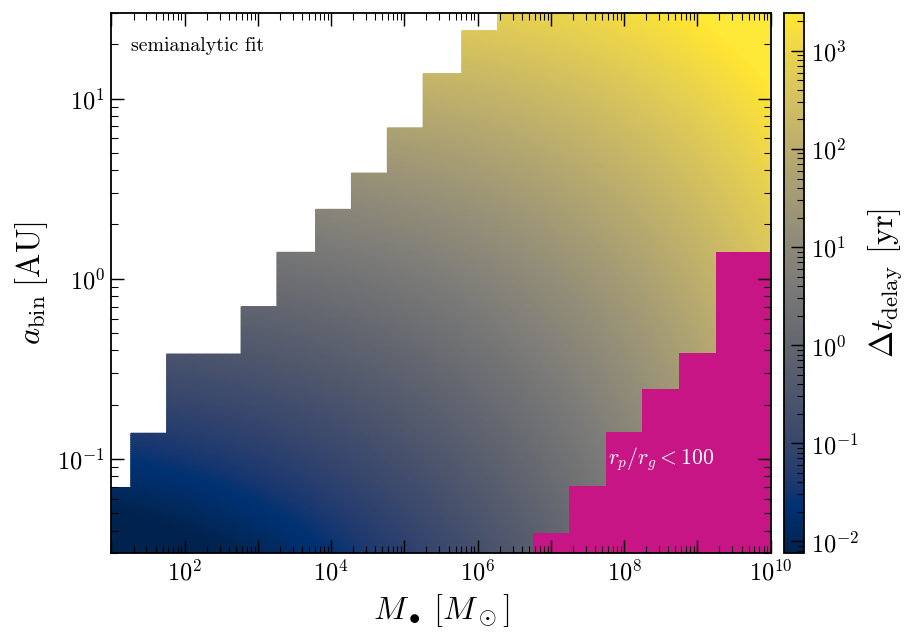

In [4]:
# ===== FIGURE: Dt_delay(M_bullet,a_bin) SMOOTH semi-analytic heatmap (fine grid) + forbidden region =====
# (M,a) delay fit  log10 Dt = d0 + d1 xM + d2 xa + d3 xM^2 + d4 xa^2 + d5 xM xa  (fit on the
# r_p >= RG_MIN r_g events; same fit as the residual/binned figures), evaluated on a fine (M,a)
# grid. Masked to the EXACT simulated footprint (the binned populated (M,a) cells, via nearest-bin).
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
RG_MIN=100.0                                                     # forbidden: median r_p/r_g < RG_MIN
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""
def edges(cc):                           # log-cell edges for the binned grid
    cc=np.log10(np.asarray(cc,float)); ee=np.empty(cc.size+1)
    ee[1:-1]=0.5*(cc[:-1]+cc[1:]); ee[0]=cc[0]-(cc[1]-cc[0])/2; ee[-1]=cc[-1]+(cc[-1]-cc[-2])/2
    return 10**ee

r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,e,frac,Dt=c("M_smbh"),c("a_bin"),c("e_bin"),c("frac"),c("Dt_delay")
good=np.isfinite(Dt)&(Dt>0)&np.isfinite(frac)&(frac>0)

# --- r_p/r_g per event from the bundle (one level up; same mu-TDE order as the CSV) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)

# --- exact simulated footprint + median r_p/r_g per binned (M,a) cell ---
Mb,ab=np.unique(M),np.unique(a)
pop=np.zeros((len(ab),len(Mb)),bool); RPG=np.full((len(ab),len(Mb)),np.nan)
for i,av in enumerate(ab):
    for j,Mv in enumerate(Mb):
        pop[i,j]=(good&np.isclose(a,av)&np.isclose(M,Mv)).sum()>=5
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])
Medg,aedg=edges(Mb),edges(ab)

# --- the delay fit ---
trust=good&(rp_rg>=RG_MIN)      # fit only on the trustworthy (non-relativistic) events
# --- Dt_delay fit (paper): log10(Dt/yr) = d0 + d1 xM + d2 xa + d3 xM^2 + d4 xa^2 + d5 xM xa,
#     xM=log10(M_bullet/Msun), xa=log10(a_bin/AU); least squares on `trust` (see the DELAY FIT cell)
xM,xa=np.log10(M[trust]),np.log10(a[trust]); y=np.log10(Dt[trust])
coef,*_=np.linalg.lstsq(np.column_stack([np.ones_like(xM),xM,xa,xM**2,xa**2,xM*xa]),y,rcond=None)
def model(M,a):                                          # -> log10(Dt/yr), vectorized
    xM,xa=np.log10(M),np.log10(a)
    return coef[0]+coef[1]*xM+coef[2]*xa+coef[3]*xM**2+coef[4]*xa**2+coef[5]*xM*xa

# ---- fine plotted grid ----
NM,NAx=240,240
MF=np.logspace(1,10,NM)                               # M_bullet [Msun]
AF=np.logspace(np.log10(0.03),np.log10(30.0),NAx)     # a_bin [AU]
# map each fine point to its binned cell, keep only cells in the simulated footprint
jx=np.clip(np.digitize(MF,Medg)-1,0,len(Mb)-1)
iy=np.clip(np.digitize(AF,aedg)-1,0,len(ab)-1)
MM,AA=np.meshgrid(MF,AF)
Z=np.where(pop[iy[:,None],jx[None,:]],10**model(MM,AA),np.nan)
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({
    "figure.dpi":130,"savefig.dpi":220,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
ax.set_axisbelow(False)                               # keep ticks/spines above the forbidden overlay
im=ax.pcolormesh(MF,AF,np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="gouraud")

# --- forbidden region: stepped per-cell overlay (populated AND median r_p/r_g < RG_MIN) ---
blk=np.where(pop&np.isfinite(RPG)&(RPG<RG_MIN),1.0,np.nan)
ax.pcolormesh(Medg,aedg,np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1,zorder=2)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mb[bj].min())+np.log10(Mb[bj].max()))); at=10**(np.median(np.log10(ab[bi])))
    ax.text(Mt,at,rf"$r_p/r_g<{int(RG_MIN)}$",color="white",ha="center",va="center",fontsize=12,fontweight="bold",zorder=3)

ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(MF[0],MF[-1]); ax.set_ylim(AF[0],AF[-1])
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=100)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,r"semianalytic fit",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black",zorder=3)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("delay_heatmap_smooth.png",bbox_inches="tight"); fig.savefig("delay_heatmap_smooth.pdf",bbox_inches="tight")
print("SMOOTH_delay_heatmap OK")

# Paper plot:

[verify] per-cell spread of log10(Dt_delay) over (e_bin,v_inf): all-populated mean=0.677 median=0.672 (182 cells)  |  USED (magenta excluded) mean=0.674 median=0.671 dex (153 cells)


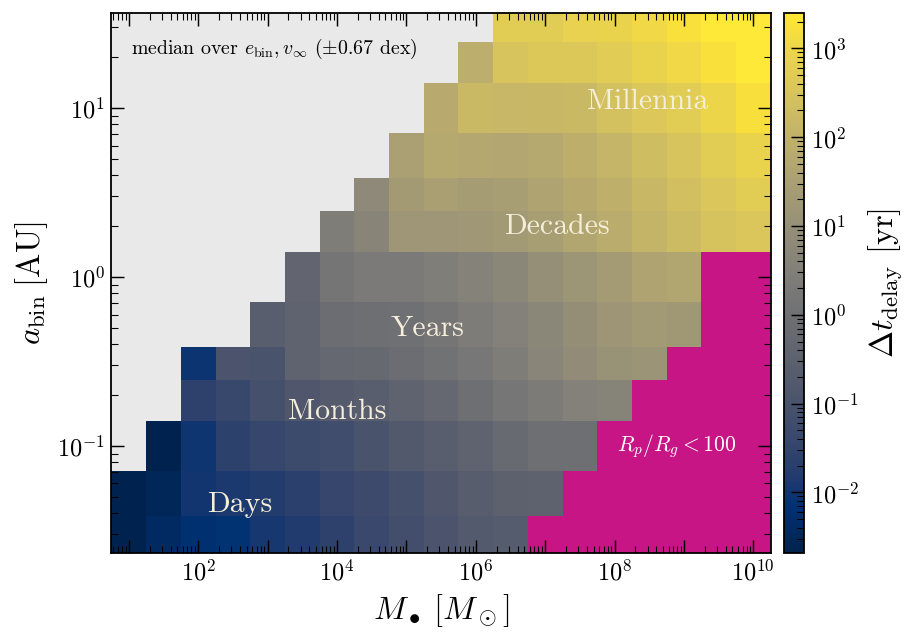

In [23]:
# ===== FIGURE: Dt_delay(M_bullet, a_bin) heatmap + relativistic-validity mask (R_p/R_g < RG_MIN) =====
import numpy as np, csv, os, h5py
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.colors import ListedColormap
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
FORBID=ListedColormap(["#C71585"]); FORBID.set_bad(alpha=0.0)   # mediumvioletred, contrasts cividis
RG_MIN=100.0     # mask cells whose median pericenter is < RG_MIN R_g (PN corr ~ R_p/R_g:
                # 100->1%, 30->3%, 10->10%, ISCO~6; below ~8 R_g debris plunge, no fallback)
def edges(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def _even_pow(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""

# --- Dt_delay from the delay table (one level up) ---
r=list(csv.DictReader(open("../../../data/bhstar/campaign2_rp10/delay_per_event.csv"))); c=lambda k:np.array([float(x[k]) for x in r])
M,a,Dt=c("M_smbh"),c("a_bin"),c("Dt_delay")

# --- pericenter depth R_p/R_g from the bundle (one level up; same mu-TDE order as the CSV) ---
BUNDLE=os.environ.get("SMBH_BUNDLE","../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(BUNDLE,"r") as f:
    R=f["results"]; mu=np.where(R["outcome"].asstr()[:]=="TDE:star2_by_bh1")[0]
    g=lambda k: R[k][mu]
    rp=np.sqrt((g("x_b1_AU")-g("x_smbh_AU"))**2+(g("y_b1_AU")-g("y_smbh_AU"))**2+(g("z_b1_AU")-g("z_smbh_AU"))**2)
assert len(mu)==len(M), f"CSV ({len(M)}) vs bundle mu-TDE ({len(mu)}) mismatch"
rp_rg=rp/((29.7847/299792.458)**2 * M)      # R_g(M_bullet)=(V1/c)^2 M  [AU]

Mg,ag=np.unique(M),np.unique(a); good=np.isfinite(Dt)&(Dt>0)
Z  =np.full((len(ag),len(Mg)),np.nan)       # median Dt_delay
RPG=np.full((len(ag),len(Mg)),np.nan)       # median R_p/R_g
SPR=np.full((len(ag),len(Mg)),np.nan)       # per-cell dispersion of log10 Dt over (e_bin, v_inf)
for i,av in enumerate(ag):
    for j,Mv in enumerate(Mg):
        m=good&np.isclose(a,av)&np.isclose(M,Mv)
        if m.sum()>=5: Z[i,j]=np.median(Dt[m]); SPR[i,j]=np.std(np.log10(Dt[m]))
        mr=np.isclose(a,av)&np.isclose(M,Mv)&np.isfinite(rp_rg)
        if mr.sum()>=5: RPG[i,j]=np.median(rp_rg[mr])

# --- systematic quoted in the label: mean per-cell log10(Dt) spread, EXCLUDING the magenta cells ---
pop=np.isfinite(SPR)
masked=np.isfinite(RPG)&(RPG<RG_MIN)
unmask=pop&(~masked)
X_SYS=float(np.nanmean(SPR[unmask]))        # disregards the relativistic (R_p/R_g<100) regime
print(f"[verify] per-cell spread of log10(Dt_delay) over (e_bin,v_inf): "
      f"all-populated mean={np.nanmean(SPR[pop]):.3f} median={np.nanmedian(SPR[pop]):.3f} "
      f"({int(pop.sum())} cells)  |  USED (magenta excluded) mean={X_SYS:.3f} "
      f"median={np.nanmedian(SPR[unmask]):.3f} dex ({int(unmask.sum())} cells)")

vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")

# --- mask the relativistic cells (populated AND R_p/R_g < RG_MIN) ---
blk=np.full_like(Z,np.nan); blk[np.isfinite(Z)&masked]=1.0
ax.pcolormesh(edges(Mg),edges(ag),np.ma.masked_invalid(blk),cmap=FORBID,shading="flat",vmin=0,vmax=1)
bi,bj=np.where(np.isfinite(blk))
if bi.size:
    Mt=10**(0.5*(np.log10(Mg[bj].min())+np.log10(Mg[bj].max()))+0.40)   # log-midpoint, nudged right
    at=10**(np.median(np.log10(ag[bi])))                                # median a of masked cells
    ax.text(Mt,at,rf"$R_p/R_g<{int(RG_MIN)}$",color="white",ha="center",va="center",
            fontsize=12,fontweight="bold")

# --- hand-placed timescale region labels ---
TLAB=[("Days",4e2,0.045),("Months",1e4,0.16),("Years",2e5,0.5),
      ("Decades",1.5e7,2.0),("Millennia",3e8,11.0)]
for name,Mc,ac in TLAB:
    ax.text(Mc,ac,name,color="#f5eeda",ha="center",va="center",
            fontsize=16.5,fontweight="bold",zorder=5)

ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_even_pow))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,rf"median over $e_{{\rm bin}},v_\infty$ ($\pm{X_SYS:.2f}$ dex)",
        transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$\Delta t_{\rm delay}$ [yr]")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("delay_Ma_validity.png",bbox_inches="tight"); fig.savefig("delay_Ma_validity.pdf",bbox_inches="tight")
plt.show()